# Ciblage des ménages avec le Machine Learning (v6)
### Enquête ménage complexe : 72 variables, décision de la vérification approfondie

Dans la version précédente (v5), le modèle apprenait à reproduire la grille de points de l'agent et son seuil de 40 points. Les scores étaient très hauts, mais c'était de la triche : le modèle recopiait la grille Excel et n'apportait rien de plus qu'Excel. Dans mon mémoire, la colonne `Score_Vuln` avait déjà été mise de côté pour la même raison, elle provoquait l'overfitting.

Dans cette version, **la grille, son score et son seuil ne sont pas donnés au modèle**. Le modèle apprend la décision de la **vérification approfondie** (visite à domicile et comité de ciblage) à partir des seules réponses de l'enquête ménage.

Pourquoi un modèle et pas seulement Excel ?
- Dans un scénario simple (une dizaine de questions oui/non), la grille Excel fait le travail.
- Avec plus de 70 variables, la grille ne peut pas tout combiner, et l'humain peut se tromper. Le modèle cherche lui-même les relations entre les réponses : consommation alimentaire, stratégies d'adaptation, revenu par personne, taille du ménage, logement, protection...
- Le modèle assiste la décision à grande échelle, il ne la remplace pas : les décisions restent revues par un superviseur.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#supprimer les warnings
import warnings
warnings.filterwarnings("ignore")

### Importer et lire les données

In [3]:
#importer les données
# le fichier est créé par le notebook generation_donnees_ciblage_v6.ipynb
df = pd.read_csv("./data/ciblage_v6.csv")
df.head()

,id_menage,date_enquete,enqueteur,localite,statut_menage,duree_deplacement_mois,nombre_deplacements_12m,sexe_chef_menage,age_chef_menage,etat_civil_chef,...,incident_securite_3_mois,biens_perdus_crise,membre_disparu_detenu,documents_identite,restriction_mouvements,assistance_3_derniers_mois,type_assistance_recue,score_grille_excel,decision_grille_excel,eligible
0,MEN_000001,2026-08-19,ENQ_19,Rutshuru,resident,NaN,NaN,homme,57,marie,...,non,non,non,oui,non,non,NaN,16,0,0
1,MEN_000002,2026-04-06,ENQ_16,Rwanguba,resident,NaN,NaN,homme,27,marie,...,non,non,non,oui,non,non,NaN,21,0,0
2,MEN_000003,2026-03-07,ENQ_05,Bambo,resident,NaN,NaN,homme,18,marie,...,non,non,non,oui,non,non,NaN,49,1,0
3,MEN_000004,2026-07-07,ENQ_14,Rwanguba,deplace,0.0,3.0,homme,26,marie,...,non,non,non,oui,non,non,NaN,30,0,1
4,MEN_000005,2026-05-14,ENQ_01,Rwanguba,retourne,NaN,5.0,femme,44,marie,...,non,non,non,oui,oui,non,NaN,32,0,0


In [4]:
#dimension des données
df.shape

(100000, 79)

In [5]:
#info sur les données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 79 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id_menage                       100000 non-null  str    
 1   date_enquete                    100000 non-null  str    
 2   enqueteur                       100000 non-null  str    
 3   localite                        100000 non-null  str    
 4   statut_menage                   100000 non-null  str    
 5   duree_deplacement_mois          36514 non-null   float64
 6   nombre_deplacements_12m         46918 non-null   float64
 7   sexe_chef_menage                100000 non-null  str    
 8   age_chef_menage                 100000 non-null  int64  
 9   etat_civil_chef                 100000 non-null  str    
 10  instruction_chef                100000 non-null  str    
 11  taille_menage                   100000 non-null  int64  
 12  enfants_moins_5             

La dataframe a 100,000 lignes et 79 colonnes.

#### Définition des données
Ces données ont été générées pour simulation (le code est dans `generateur_ciblage_v6.py`). Chaque ligne représente un ménage enquêté avec Kobo, les colonnes sont les réponses à l'enquête ménage, inspirée d'une MSNA (questionnaire multisectoriel). Il n'y a pas de GPS ni de données externes : tout vient de l'enquête ménage.

Après l'enquête, deux choses se passent :
1. l'agent calcule le score de la **grille Excel** de l'ONG (colonnes `score_grille_excel` et `decision_grille_excel`, seuil de 40 points) ;
2. une équipe fait la **vérification approfondie** (visite à domicile + comité de ciblage) et décide si le ménage est éligible : c'est la variable cible `eligible`.

#### Les variables

| Thème | Variables | Type |
|---|---|---|
| Identification | `id_menage`, `date_enquete`, `enqueteur`, `localite` | Non utilisées par le modèle |
| Profil | `statut_menage`, `duree_deplacement_mois`, `nombre_deplacements_12m`, `sexe_chef_menage`, `age_chef_menage`, `etat_civil_chef`, `instruction_chef` | Catégorielles et numériques |
| Composition | `taille_menage`, `enfants_moins_5`, `enfants_5_17`, `personnes_60_plus`, `enfants_non_scolarises`, `femme_enceinte_allaitante`, `membre_handicap`, `membre_maladie_chronique`, `enfant_non_accompagne_heberge` | Numériques et binaires (Oui/Non) |
| Logement et biens | `type_logement`, `statut_occupation`, `nombre_pieces`, `articles_essentiels`, `possede_betail`, `acces_terre_cultivable`, `toit_etanche`, `source_eclairage`, `possede_telephone` | Catégorielles et numériques |
| Eau et hygiène | `source_eau`, `temps_collecte_eau_min`, `type_latrine`, `savon_disponible` | Catégorielles et numériques |
| Santé et nutrition | `enfant_malade_2_semaines`, `acces_soins`, `vaccination_enfants_a_jour`, `enfant_malnutrition_depiste` | Catégorielles |
| Alimentation | nombre de jours de consommation de 8 groupes d'aliments sur 7 jours (`jours_cereales` ... `jours_sucre`), `stock_nourriture_jours`, `repas_par_jour`, `jours_sans_nourriture_7j` | Numériques |
| Stratégies d'adaptation | 5 stratégies alimentaires en jours (`rcsi_...`) et 9 stratégies sur les moyens d'existence (`lcs_...` : emprunt, vente de biens, semences, retrait de l'école, mendicité...) | Numériques et binaires |
| Moyens d'existence | `source_revenu`, `membres_avec_revenu`, `perte_revenu_6_mois`, `revenu_30j_usd`, `part_depenses_alimentation_pct`, `dette_usd`, `epargne_disponible` | Catégorielles et numériques |
| Protection | `incident_securite_3_mois`, `biens_perdus_crise`, `membre_disparu_detenu`, `documents_identite`, `restriction_mouvements` | Binaires |
| Assistance | `assistance_3_derniers_mois`, `type_assistance_recue` | Catégorielles |
| Grille de l'agent | `score_grille_excel`, `decision_grille_excel` | **Retirées avant l'entrainement** |
| Cible | `eligible` | Binaire (1 = éligible après vérification) |

Au total, 72 variables de l'enquête ménage sont données au modèle.

### <font color = 'orange'>Exploration des données<font>

##### <font color = 'magenta'>Sélection des variables

In [6]:
#selection des variables catégorielles
cat_data = df.select_dtypes(exclude='number')
cat_data.head()

,id_menage,date_enquete,enqueteur,localite,statut_menage,sexe_chef_menage,etat_civil_chef,instruction_chef,femme_enceinte_allaitante,membre_handicap,...,source_revenu,perte_revenu_6_mois,epargne_disponible,incident_securite_3_mois,biens_perdus_crise,membre_disparu_detenu,documents_identite,restriction_mouvements,assistance_3_derniers_mois,type_assistance_recue
0,MEN_000001,2026-08-19,ENQ_19,Rutshuru,resident,homme,marie,primaire,non,non,...,petit_commerce,non,oui,non,non,non,oui,non,non,NaN
1,MEN_000002,2026-04-06,ENQ_16,Rwanguba,resident,homme,marie,primaire,non,non,...,agriculture,non,non,non,non,non,oui,non,non,NaN
2,MEN_000003,2026-03-07,ENQ_05,Bambo,resident,homme,marie,secondaire,oui,non,...,agriculture,non,non,non,non,non,oui,non,non,NaN
3,MEN_000004,2026-07-07,ENQ_14,Rwanguba,deplace,homme,marie,aucun,non,non,...,travail_journalier,non,non,non,non,non,oui,non,non,NaN
4,MEN_000005,2026-05-14,ENQ_01,Rwanguba,retourne,femme,marie,primaire,oui,non,...,agriculture,oui,non,non,non,non,oui,oui,non,NaN


In [7]:
# sélection des variables quantitatives
num_data = df.select_dtypes(include='number')
num_data.head()

,duree_deplacement_mois,nombre_deplacements_12m,age_chef_menage,taille_menage,enfants_moins_5,enfants_5_17,personnes_60_plus,enfants_non_scolarises,nombre_pieces,articles_essentiels,...,rcsi_reduction_portions,rcsi_adultes_pour_enfants,rcsi_moins_de_repas,membres_avec_revenu,revenu_30j_usd,part_depenses_alimentation_pct,dette_usd,score_grille_excel,decision_grille_excel,eligible
0,NaN,NaN,57,2,0,1,0,0,6,4,...,2,0,0,1,104,47,0,16,0,0
1,NaN,NaN,27,2,1,0,0,0,4,4,...,2,1,1,1,51,46,50,21,0,0
2,NaN,NaN,18,4,1,0,0,0,0,0,...,2,1,3,2,51,66,69,49,1,0
3,0.0,3.0,26,5,0,2,0,1,2,4,...,3,0,1,1,30,50,0,30,0,1
4,NaN,5.0,44,4,1,0,0,0,4,2,...,1,0,1,2,75,48,116,32,0,0


In [8]:
cat_data.shape, num_data.shape

((100000, 45), (100000, 34))

##### <font color = 'magenta'>Exploration des variables catégorielles

In [9]:
# décrire les variables catégorielles
cat_data.describe()

,id_menage,date_enquete,enqueteur,localite,statut_menage,sexe_chef_menage,etat_civil_chef,instruction_chef,femme_enceinte_allaitante,membre_handicap,...,source_revenu,perte_revenu_6_mois,epargne_disponible,incident_securite_3_mois,biens_perdus_crise,membre_disparu_detenu,documents_identite,restriction_mouvements,assistance_3_derniers_mois,type_assistance_recue
count,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,...,100000,100000,100000,100000,100000,100000,100000,100000,100000,22629
unique,100000,200,20,6,4,2,4,4,2,2,...,5,2,2,2,2,2,2,2,2,5
top,MEN_000001,2026-07-07,ENQ_09,Binza,resident,homme,marie,primaire,non,non,...,travail_journalier,non,non,non,non,non,oui,non,non,vivres
freq,1,569,5137,16745,40650,70569,80625,43821,77834,90797,...,31576,78361,73583,84712,75800,96187,73324,73568,77371,8046


In [10]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.values, text_auto=True, title=col)
  fig.show()

In [11]:
# Countplots des principales variables catégorielles
# il y a 45 colonnes catégorielles, on regarde celles qui comptent le plus dans le ciblage
cols = ['localite', 'statut_menage', 'sexe_chef_menage', 'type_logement', 'source_revenu', 'source_eau', 'acces_soins', 'assistance_3_derniers_mois']
for col in cols:
    countplot_func(col)

##### <font color = 'magenta'>La variable cible

In [12]:
# Nombre d'observations dans chaque classe de la variable cible
df.eligible.value_counts()

eligible
0    70000
1    30000
Name: count, dtype: int64

In [13]:
countplot_func("eligible")

30 % des ménages sont éligibles après la vérification. Les classes sont déséquilibrées (30 % / 70 %) : on ne regardera pas seulement l'accuracy, mais aussi le F1 score, le recall (ménages éligibles retrouvés) et la précision.

In [14]:
# taux d'éligibilité selon une variable
def taux_func(col):
  val = df.groupby(col)['eligible'].mean().sort_values()
  fig = px.bar(x=val.index, y=val.values, color=val.values, text_auto='.1%', title=f"Taux d'éligibilité par {col}")
  fig.show()

In [15]:
for col in ['localite', 'statut_menage', 'type_logement', 'source_revenu']:
    taux_func(col)

Les ménages déplacés sont éligibles plus souvent (55 %) que les résidents (14 %), et Birambizo (44 %) plus souvent que Rutshuru (16 %). Mais aucune modalité ne donne la décision à elle seule : 45 % des déplacés ne sont pas éligibles.

##### <font color = 'magenta'>Exploration des variables quantitatives

In [16]:
# décrire les variables quantitatives
num_data.describe().T

,count,mean,std,min,25%,50%,75%,max
duree_deplacement_mois,36514.0,7.305773,7.786861,0.0,2.0,5.0,10.0,102.0
nombre_deplacements_12m,46918.0,2.154887,1.092650,1.0,1.0,2.0,3.0,9.0
age_chef_menage,100000.0,40.313830,13.738464,14.0,30.0,40.0,50.0,90.0
taille_menage,100000.0,6.006550,2.236528,1.0,4.0,6.0,7.0,17.0
enfants_moins_5,100000.0,1.104150,1.054397,0.0,0.0,1.0,2.0,9.0
enfants_5_17,100000.0,1.723780,1.309702,0.0,1.0,2.0,3.0,9.0
personnes_60_plus,100000.0,0.436370,0.655268,0.0,0.0,0.0,1.0,5.0
enfants_non_scolarises,100000.0,0.470690,0.706134,0.0,0.0,0.0,1.0,5.0
nombre_pieces,100000.0,2.955980,1.495842,0.0,2.0,3.0,4.0,8.0
articles_essentiels,100000.0,3.092030,1.227826,0.0,2.0,3.0,4.0,5.0


In [17]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df, x = col, color = 'eligible', title = col)
    fig.show()

In [18]:
# boxplots de quelques variables quantitatives selon l'éligibilité
for col in ['taille_menage', 'revenu_30j_usd', 'dette_usd', 'stock_nourriture_jours', 'part_depenses_alimentation_pct', 'temps_collecte_eau_min']:
    boxplot_func(col)

Le revenu, la dette et les réserves de nourriture ont des valeurs extrêmes. Elles sont réalistes (quelques ménages ont un salaire ou un commerce), on ne les remplace donc pas par la médiane : ce sont justement ces écarts qui distinguent les ménages. Le RobustScaler limitera leur effet sur les modèles sensibles à l'échelle (KNN, régression logistique, SVM).

In [19]:
# corrélation des variables quantitatives avec la variable cible
corr = num_data.corr()['eligible'].drop(['eligible', 'score_grille_excel', 'decision_grille_excel']).sort_values()
fig = px.bar(x=corr.values, y=corr.index, color=corr.values, orientation='h', height=900, title="Corrélation avec l'éligibilité")
fig.show()

Aucune variable n'explique seule l'éligibilité : la plus forte corrélation est d'environ 0,50 (part des dépenses consacrée à la nourriture), puis viennent les stratégies d'adaptation alimentaires (rCSI) et le revenu. La décision dépend de la **combinaison** des réponses. C'est exactement le cas où un modèle est utile par rapport à une grille de points.

##### <font color = 'magenta'>Et le score de la grille Excel ?

In [20]:
# distribution du score de la grille Excel selon la décision de la vérification
fig = px.histogram(df, x='score_grille_excel', color='eligible', barmode='overlay', nbins=60,
                   title="Score de la grille Excel selon la décision de la vérification (seuil 40 points)")
fig.add_vline(x=40, line_dash='dash')
fig.show()

In [21]:
pd.crosstab(df.eligible, df.decision_grille_excel, rownames=['vérification'], colnames=['grille Excel'])

grille Excel,0,1
vérification,,
0,61241,8759
1,12643,17357


Les deux distributions se chevauchent beaucoup : plus de 9 000 ménages éligibles après vérification ont moins de 40 points dans la grille, et plus de 11 000 ménages non éligibles ont 40 points ou plus. La grille regarde une quinzaine de questions et additionne des points, elle ne voit pas le reste du questionnaire.

Ces colonnes **ne seront pas données au modèle** : sinon le modèle recopierait la grille (overfitting), comme avec `Score_Vuln` dans la première version. Elles servent seulement de point de comparaison à la fin.

### Préparation des données

##### <font color = 'blue'> Valeurs manquantes

In [22]:
df.isnull().sum()[df.isnull().sum() > 0]

duree_deplacement_mois     63486
nombre_deplacements_12m    53082
type_assistance_recue      77371
dtype: int64

Ce ne sont pas de vraies valeurs manquantes : ce sont des questions conditionnelles de Kobo qui ne sont pas posées à tout le monde.
- `duree_deplacement_mois` : posée seulement aux ménages déplacés ;
- `nombre_deplacements_12m` : posée seulement aux déplacés et aux retournés ;
- `type_assistance_recue` : posée seulement si le ménage a reçu une assistance.

On les remplace par une valeur qui veut dire "non applicable" : -1 pour les nombres (0 a déjà un sens : déplacé depuis moins d'un mois), `non_applicable` pour le type d'assistance.

In [23]:
df['duree_deplacement_mois'] = df['duree_deplacement_mois'].fillna(-1)
df['nombre_deplacements_12m'] = df['nombre_deplacements_12m'].fillna(-1)
df['type_assistance_recue'] = df['type_assistance_recue'].fillna('non_applicable')
df.isnull().sum().sum()

np.int64(0)

##### <font color = 'blue'> Suppression des colonnes qui ne servent pas à la prédiction

In [24]:
# id_menage, date_enquete, enqueteur : identification de l'enquête
# localite : sert à répartir le budget par zone, pas à décider (on ne cible pas un village plutôt qu'un autre)
# score_grille_excel et decision_grille_excel : c'est la grille de l'agent, elle donnerait la réponse au modèle (overfitting)
df_model = df.drop(['id_menage', 'date_enquete', 'enqueteur', 'localite', 'score_grille_excel', 'decision_grille_excel'], axis=1)
df_model.shape

(100000, 73)

##### <font color = 'blue'> Encodage des variables catégorielles

In [25]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder

cat_cols = df_model.select_dtypes(exclude='number').columns

#Liste des encodeurs
encoders = []

for col in cat_cols:
    encoder = LabelEncoder()
    df_model[col] = encoder.fit_transform(df_model[col])
    encoders.append(encoder)

df_model.head()

,statut_menage,duree_deplacement_mois,nombre_deplacements_12m,sexe_chef_menage,age_chef_menage,etat_civil_chef,instruction_chef,taille_menage,enfants_moins_5,enfants_5_17,...,dette_usd,epargne_disponible,incident_securite_3_mois,biens_perdus_crise,membre_disparu_detenu,documents_identite,restriction_mouvements,assistance_3_derniers_mois,type_assistance_recue,eligible
0,2,-1.0,-1.0,1,57,2,1,2,0,1,...,0,1,0,0,0,1,0,0,4,0
1,2,-1.0,-1.0,1,27,2,1,2,1,0,...,50,0,0,0,0,1,0,0,4,0
2,2,-1.0,-1.0,1,18,2,2,4,1,0,...,69,0,0,0,0,1,0,0,4,0
3,0,0.0,3.0,1,26,2,0,5,0,2,...,0,0,0,0,0,1,0,0,4,1
4,3,-1.0,5.0,0,44,2,1,4,1,0,...,116,0,0,0,0,1,1,0,4,0


In [26]:
#Tester encoders
encoders[list(cat_cols).index('type_logement')].classes_

array(['abri_fortune', 'heberge_famille', 'maison_correcte',
       'maison_endommagee', 'sans_abri'], dtype=object)

##### <font color = 'blue'> Fractionnement et normalisation

In [27]:
# Fractionner les données en variables prédicteurs (x) et variable cible (y)
noms_variables = df_model.drop('eligible', axis=1).columns
x = df_model.drop('eligible', axis=1).values # variables prédicteurs
y = df_model['eligible'].values # variable cible
idx = df_model.index.values # pour retrouver les ménages après le fractionnement
len(noms_variables), x.shape, y.shape

(72, (100000, 72), (100000,))

In [28]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
# train : données d'entrainement, val : données pour évaluer chaque modèle et test : données pour tester le modèle le plus performant
# stratify garde 30% d'éligibles dans chaque partie
from sklearn.model_selection import train_test_split
x_train, x_vt, y_train, y_vt, idx_train, idx_vt = train_test_split(x, y, idx, train_size = 0.8, stratify = y, random_state = 42) # 80% / 20%
x_val, x_test, y_val, y_test, idx_val, idx_test = train_test_split(x_vt, y_vt, idx_vt, train_size = 0.5, stratify = y_vt, random_state = 42) # 10% / 10%

In [29]:
# Normaliser les données
# le normaliseur est appris sur les données d'entrainement seulement
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaler.fit(x_train)
x_train = scaler.transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)
x_train[:2]

array([[ 0.        ,  0.        ,  0.        ,  0.        , -0.3       ,
         0.        ,  0.5       , -1.        ,  0.        , -1.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  1.        , -0.5       ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  1.        , -1.        ,
         0.        , -0.1875    ,  1.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.5       ,
         1.        ,  0.        ,  0.        ,  0.        , -0.5       ,
         0.        ,  1.04545455,  1.        ,  0.        ,  0.        ,
        -0.5       , -0.5       , -0.5       , -0.5       ,  1.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.33333333,  0.        ,
         0.        ,  1.96428571,  0.16666667, -0.26136364,  0.        ,
         1.        ,  0.        ,  0.        ,  0. 

In [30]:
# dimension des données train, validation et test
x_train.shape, x_val.shape, x_test.shape

((80000, 72), (10000, 72), (10000, 72))

In [31]:
# échantillon pour la recherche des paramètres optimaux
# avec 80 000 ménages et 72 variables, le GridSearch sur KNN, SVM, RF et GB prendrait des heures :
# on cherche les paramètres sur 20 000 ménages, puis on entraine sur toutes les données d'entrainement
x_grid, y_grid = x_train[:20000], y_train[:20000]

### Modélisation

In [32]:
# Accuracy, F1 score, recall et précision du modèle
from sklearn.metrics import f1_score, accuracy_score, recall_score, precision_score
score_models = [] # contiendra les scores de tous les modèles
def evaluation(model, model_name, type_data, x_data, y_data):
  #predictions
  y_pred = model.predict(x_data)

  dic = dict()
  dic['model'] = model_name
  dic['accuracy'] = accuracy_score(y_data, y_pred)
  dic['f1_score'] = f1_score(y_data, y_pred)
  dic['recall'] = recall_score(y_data, y_pred)
  dic['precision'] = precision_score(y_data, y_pred)
  dic['type_data'] = type_data

  print(f"Accuracy: {dic['accuracy']:.3f} -- F1 score: {dic['f1_score']:.3f} -- Recall: {dic['recall']:.3f} -- Precision: {dic['precision']:.3f}")
  return dic

In [33]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def confusion_matrix_func (model, x_data, y_data):
  # y_pred:  prédictions du modèle
  y_pred = model.predict(x_data)
  # Confusion matrix
  cnf_matr = confusion_matrix(y_data, y_pred, labels=[0,1])

  # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
  disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                display_labels=['Non Eligible(0)','Eligible(1)'])
  disp.plot() # Afficher la matrice de confusion
  plt.title('Matrice de confusion') # Définir le titre
  plt.show() # Afficher la figure

#### <font color = 'teal'>K nearest neighbor (K-NN)

In [34]:
# Importer KNeighborsClassifier et GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
# initialiser le modèle knn
knn = KNeighborsClassifier()
# choisir une rangée de valeurs impaires de 3 à 29
params = {'n_neighbors': range(3, 30, 2)}

# Instantier le modèle GridSearchCV
grid = GridSearchCV(knn, params, cv = 3, n_jobs = -1)
# lancer la recherche
grid.fit(x_grid, y_grid)
grid.best_params_

{'n_neighbors': 19}

In [35]:
# Instantier le modèle avec le k optimal
knn_model = KNeighborsClassifier(n_neighbors = grid.best_params_['n_neighbors'])
# Entrainer le modèle
knn_model.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",19
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [36]:
#echantillon de 10 ménages pour tester la performance du model
x_test_10 = x_test[10:20]
y_test_10 = y_test[10:20]
y_pred_10 = knn_model.predict(x_test_10)

#Afficher les prédictions
for i in range(10):
  print(f"Le ménage {i+1} est considéré comme {'Non éligible' if y_pred_10[i] == 0 else 'Eligible'} - {'Non éligible' if y_test_10[i] == 0 else 'Eligible'}")

Le ménage 1 est considéré comme Non éligible - Non éligible
Le ménage 2 est considéré comme Eligible - Eligible
Le ménage 3 est considéré comme Non éligible - Non éligible
Le ménage 4 est considéré comme Non éligible - Non éligible
Le ménage 5 est considéré comme Eligible - Eligible
Le ménage 6 est considéré comme Non éligible - Non éligible
Le ménage 7 est considéré comme Non éligible - Non éligible
Le ménage 8 est considéré comme Non éligible - Non éligible
Le ménage 9 est considéré comme Non éligible - Non éligible
Le ménage 10 est considéré comme Non éligible - Non éligible


In [37]:
# Evaluation sur les données test
knn_score = evaluation(knn_model, 'KNN', 'test', x_test, y_test)
score_models.append(knn_score)

Accuracy: 0.887 -- F1 score: 0.779 -- Recall: 0.667 -- Precision: 0.937


In [38]:
#Evaluation sur les données de validation
knn_score_val = evaluation(knn_model, 'KNN', 'validation', x_val, y_val)
score_models.append(knn_score_val)

Accuracy: 0.881 -- F1 score: 0.768 -- Recall: 0.652 -- Precision: 0.933


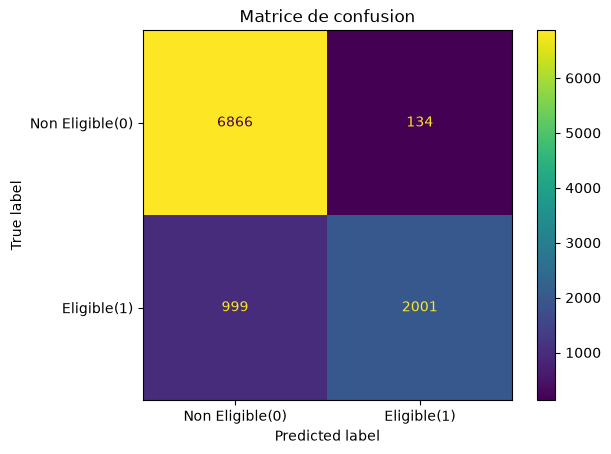

In [39]:
confusion_matrix_func(knn_model, x_test, y_test)

Le KNN souffre du nombre de variables : avec 72 dimensions, les distances entre ménages deviennent peu parlantes (fléau de la dimension).

## 2. <font color = 'teal'>Logistic Regression<font>

In [40]:
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression
# dictionnaire params
params = {"C": np.logspace(-3, 2, 6), "penalty": ['l1', 'l2'], "solver": ['liblinear']}
# instantier le modèle Logistic regression
lg = LogisticRegression(max_iter = 3000)
# instantier le modèle gridsearch
grid = GridSearchCV(lg, params, cv = 3, n_jobs = -1)
# lancer la recherche
grid.fit(x_grid, y_grid)
grid.best_params_

{'C': np.float64(1.0), 'penalty': 'l1', 'solver': 'liblinear'}

In [41]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg = LogisticRegression(max_iter = 3000, **grid.best_params_)
lg.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(1.0)
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net pe

### Evaluation Du Logistic Regression

In [42]:
score_lg_test = evaluation(lg, 'LG', 'test', x_test, y_test)
score_models.append(score_lg_test)

Accuracy: 0.948 -- F1 score: 0.914 -- Recall: 0.910 -- Precision: 0.918


In [43]:
### Evaluation sur les données validation
score_lg_val = evaluation(lg, 'LG', 'validation', x_val, y_val)
score_models.append(score_lg_val)

Accuracy: 0.949 -- F1 score: 0.914 -- Recall: 0.912 -- Precision: 0.916


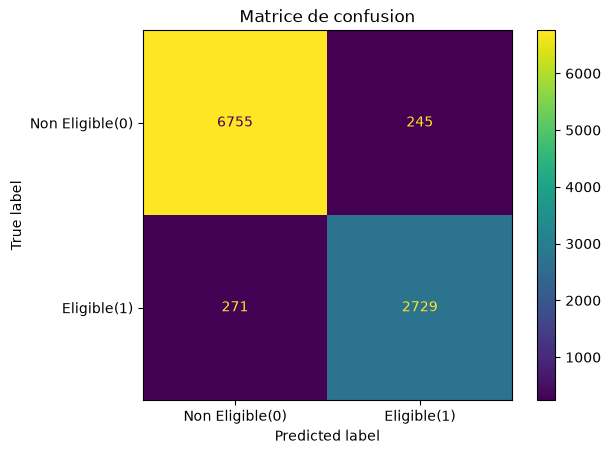

In [44]:
confusion_matrix_func(lg, x_test, y_test)

In [45]:
# coefficients de la régression logistique
def COEFS_BAR(model):
  coefs = pd.Series(model.coef_[0], index = noms_variables).sort_values()
  fig = px.bar(x = coefs.values, y = coefs.index, color = coefs.values, orientation = 'h', height = 1200, title = "Coefficients de la régression logistique")
  fig.show()

COEFS_BAR(lg)

La régression logistique additionne des effets, comme une grille de points, mais avec des poids appris sur les données. Elle fait déjà beaucoup mieux que la grille Excel. Elle ne peut cependant pas représenter les combinaisons (par exemple un revenu faible qui pèse plus lourd dans un grand ménage sans réserves de nourriture).

### <font color = 'teal'>Support Vectors Machines (SVM)<font>

In [46]:
# Recherche des paramètres optimaux pour le svm
# SVM linéaire : le SVM à noyau rbf est trop lent sur 80 000 ménages
from sklearn.svm import LinearSVC
param_ = {'C': [0.01, 0.1, 1, 10]}
svm = LinearSVC(dual = False, max_iter = 5000)
grid_ = GridSearchCV(svm, param_, cv = 3, n_jobs = -1)
grid_.fit(x_grid, y_grid)
grid_.best_params_

{'C': 1}

In [47]:
# Entrainer svm en utilisant les paramètres optimaux
svm_model = LinearSVC(dual = False, max_iter = 5000, C = grid_.best_params_['C'])
svm_model.fit(x_train, y_train)

,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",5000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0


#### Evaluation SVM

In [48]:
score_svm_test = evaluation(svm_model, 'SVM', 'test', x_test, y_test)
score_models.append(score_svm_test)

Accuracy: 0.948 -- F1 score: 0.912 -- Recall: 0.907 -- Precision: 0.918


In [49]:
score_svm_validation = evaluation(svm_model, 'SVM', 'validation', x_val, y_val)
score_models.append(score_svm_validation)

Accuracy: 0.948 -- F1 score: 0.913 -- Recall: 0.911 -- Precision: 0.915


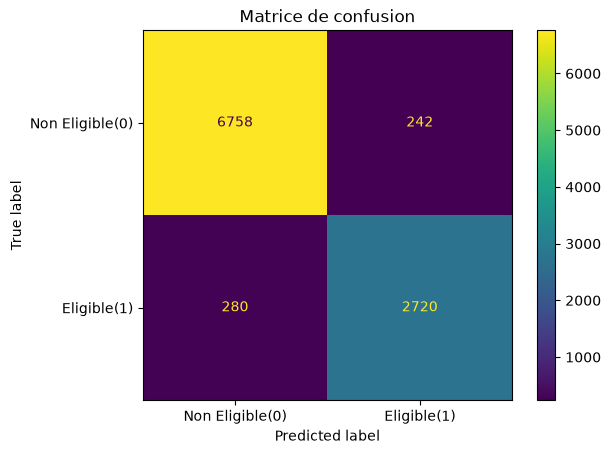

In [50]:
confusion_matrix_func(svm_model, x_test, y_test)

### <font color = 'teal'>Decision Tree<font>

In [51]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(4, 21, 2)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier(random_state = 42)
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = 3, n_jobs = -1)
# entrainer le modèle (l'arbre est rapide, on cherche sur toutes les données d'entrainement)
grid__.fit(x_train, y_train)
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(10)}

In [52]:
# Entrainer le modèle en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(random_state = 42, **grid__.best_params_)
dt_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(10)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of

#### Score de Decision Tree sur les données test et de validation

In [53]:
#Score données test
evaluation_dt_test = evaluation(dt_model, 'DT', 'test', x_test, y_test)
score_models.append(evaluation_dt_test)

Accuracy: 0.881 -- F1 score: 0.798 -- Recall: 0.786 -- Precision: 0.811


In [54]:
#Score données validation
evaluation_dt_val = evaluation(dt_model, 'DT', 'validation', x_val, y_val)
score_models.append(evaluation_dt_val)

Accuracy: 0.880 -- F1 score: 0.794 -- Recall: 0.770 -- Precision: 0.819


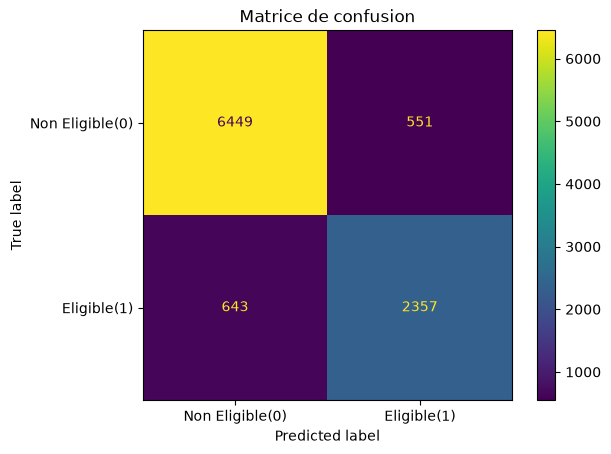

In [55]:
confusion_matrix_func(dt_model, x_test, y_test)

### <font color = 'teal'>Random Forest<font>

In [56]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = {
    'n_estimators': [100, 200],
    'max_depth' : [10, 20, None],
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier(random_state = 42)
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv = 3, n_jobs = -1)
# entrainer le modèle
grid.fit(x_grid, y_grid)
grid.best_params_

{'criterion': 'entropy', 'max_depth': 20, 'n_estimators': 200}

In [57]:
# Entrainer Random Forest en utilisant les paramètres optimaux
rf = RandomForestClassifier(random_state = 42, n_jobs = -1, **grid.best_params_)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

#### Evaluation Random Forest

In [58]:
#Evaluation sur les données test
rf_score_test = evaluation(rf, 'RF', 'test', x_test, y_test)
score_models.append(rf_score_test)

Accuracy: 0.922 -- F1 score: 0.864 -- Recall: 0.820 -- Precision: 0.912


In [59]:
#Evaluation sur les données validation
rf_score_val = evaluation(rf, 'RF', 'validation', x_val, y_val)
score_models.append(rf_score_val)

Accuracy: 0.923 -- F1 score: 0.865 -- Recall: 0.822 -- Precision: 0.913


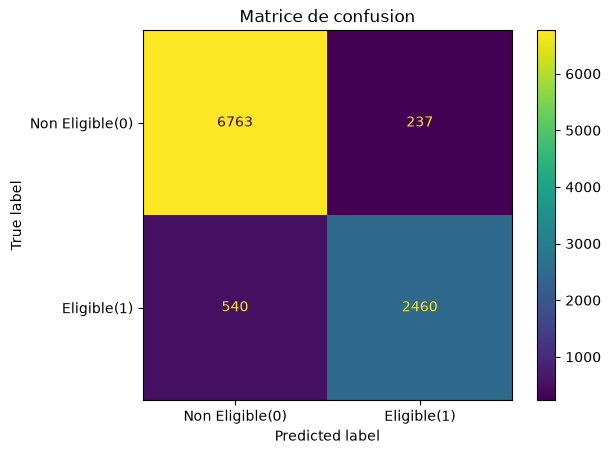

In [60]:
confusion_matrix_func(rf, x_test, y_test)

### <font color = 'teal'>Gradient Boosting<font>

In [61]:
# Recherche des paramètres optimaux pour Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier
# dictionnaire des params
params_ = { "n_estimators": [100, 200],
              "max_depth": [3, 5]}
# instantier le modèle Gradient Boost
gb = GradientBoostingClassifier(random_state = 42)
# instantier le modèle gridsearch
grid_ = GridSearchCV(estimator=gb, param_grid=params_, cv = 3, n_jobs = -1)
# entrainer le modèle
grid_.fit(x_grid, y_grid)
grid_.best_params_

{'max_depth': 5, 'n_estimators': 200}

In [62]:
# Entrainer Gradient Boosting en utilisant les paramètres optimaux
gb = GradientBoostingClassifier(random_state = 42, **grid_.best_params_)
gb.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [63]:
eval_gb_test = evaluation(gb, 'GB', 'test', x_test, y_test)
score_models.append(eval_gb_test)

Accuracy: 0.964 -- F1 score: 0.939 -- Recall: 0.922 -- Precision: 0.956


Evaluation sur les données de validation

In [64]:
eval_gb_val = evaluation(gb, 'GB', 'validation', x_val, y_val)
score_models.append(eval_gb_val)

Accuracy: 0.969 -- F1 score: 0.947 -- Recall: 0.930 -- Precision: 0.965


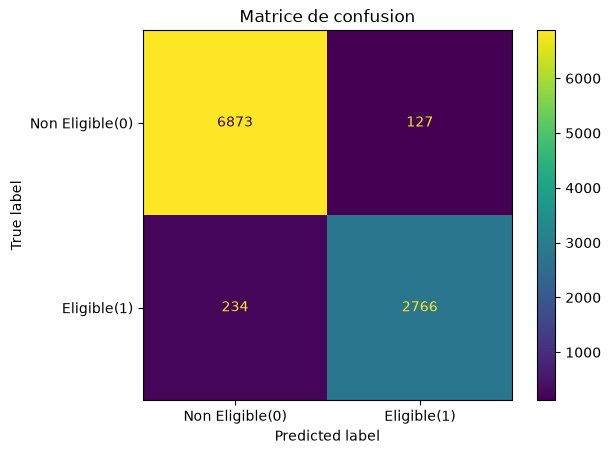

In [65]:
confusion_matrix_func(gb, x_test, y_test)

### <font color = 'teal'>XGBoost<font>

In [66]:
# Recherche des paramètres optimaux pour XGBoost
from xgboost import XGBClassifier
# dictionnaire des params
# XGBoost est rapide : on cherche sur toutes les données d'entrainement
params__ = {  "n_estimators": [1000, 3000],
              "max_depth": [3, 5]}
# instantier le modèle XGBoost
xgb = XGBClassifier(learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, random_state = 42)
# instantier le modèle gridsearch
grid__ = GridSearchCV(estimator=xgb, param_grid=params__, cv = 3)
# entrainer le modèle
grid__.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5], 'n_estimators': [1000, 3000]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information print

In [67]:
# afficher les paramètres optimaux
grid__.best_params_

{'max_depth': 3, 'n_estimators': 3000}

In [68]:
# Entrainer le modèle en utilisant les paramètres optimaux
xgb = XGBClassifier(learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, random_state = 42, **grid__.best_params_)
xgb.fit(x_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


#### Evaluation XGBoost

In [69]:
#Evaluation XGB données de test
eval_xgb_test = evaluation(xgb, 'XGB','test', x_test, y_test)
score_models.append(eval_xgb_test)

Accuracy: 0.981 -- F1 score: 0.969 -- Recall: 0.962 -- Precision: 0.976


In [70]:
#Evaluation XGB données de validation
eval_xgb_val = evaluation(xgb, 'XGB','validation', x_val, y_val)
score_models.append(eval_xgb_val)

Accuracy: 0.980 -- F1 score: 0.966 -- Recall: 0.963 -- Precision: 0.968


#### Matrice de confusion XGBoost

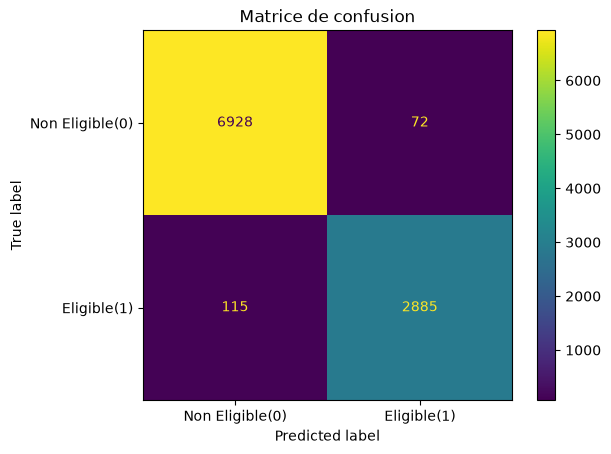

In [71]:
confusion_matrix_func(xgb, x_test, y_test)

#### Recherche du model le plus performant

In [72]:
def model_viz(data, metric, title):
    # Création du graphique
    fig = px.bar(
        x=data.model,
        y=data[metric],
        color=data[metric],
        text_auto='.2%',
        title=title
    )

    # Trouver le pic
    max_idx = data[metric].idxmax()
    max_model = data.loc[max_idx, 'model']
    max_value = data.loc[max_idx, metric]

    # Ajouter une annotation
    fig.add_annotation(
        x=max_model,
        y=max_value,
        text="⬆️ Meilleure score",
        showarrow=True,
        arrowhead=2,
        ax=0,
        ay=-40,
        font=dict(color="black", size=12)
    )

    fig.show()

In [73]:
df_score_models = pd.DataFrame(score_models)
df_score_test = df_score_models[df_score_models["type_data"] == "test"]
df_score_val = df_score_models[df_score_models["type_data"] == "validation"]
df_score_test

,model,accuracy,f1_score,recall,precision,type_data
0,KNN,0.8867,0.779357,0.667000,0.937237,test
2,LG,0.9484,0.913626,0.909667,0.917619,test
4,SVM,0.9478,0.912445,0.906667,0.918298,test
6,DT,0.8806,0.797901,0.785667,0.810523,test
8,RF,0.9223,0.863612,0.820000,0.912125,test
10,GB,0.9639,0.938741,0.922000,0.956101,test
12,XGB,0.9813,0.968608,0.961667,0.975651,test


In [74]:
model_viz(df_score_test, "f1_score", "F1 Score on test data")

In [75]:
model_viz(df_score_val, "f1_score", "F1 Score on validation data")

In [76]:
model_viz(df_score_test, "accuracy", "Accuracy on test data")

### Quel model a un meilleur RECALL?

In [77]:
model_viz(df_score_test, "recall", "Recall score on test data")

In [78]:
model_viz(df_score_val, "recall", "Recall score on validation data")

### Quel model a la meilleur precision?

In [79]:
model_viz(df_score_test, "precision", "Precision score on test data")

In [80]:
model_viz(df_score_val, "precision", "Precision score on Validation data")

## Le model le plus performant est XGB

#### Le score est-il stable ?
Un bon score sur un seul découpage peut être de la chance. On vérifie avec une validation croisée en 5 parties sur les données d'entrainement : chaque partie sert une fois de test.

In [81]:
from sklearn.model_selection import cross_validate
cv_xgb = cross_validate(XGBClassifier(learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, random_state = 42, **grid__.best_params_),
                        x_train, y_train, cv = 5, scoring = ['accuracy', 'f1', 'recall', 'precision'])
df_cv = pd.DataFrame(cv_xgb).filter(like = 'test_')
df_cv.columns = ['accuracy', 'f1_score', 'recall', 'precision']
df_cv

,accuracy,f1_score,recall,precision
0,0.980062,0.966593,0.961458,0.971784
1,0.980812,0.967904,0.964375,0.971459
2,0.978688,0.964416,0.962708,0.966130
3,0.980563,0.967417,0.961875,0.973024
4,0.980313,0.967129,0.965417,0.968848


In [82]:
df_cv.describe().loc[['mean', 'min', 'max']]

,accuracy,f1_score,recall,precision
mean,0.980088,0.966692,0.963167,0.970249
min,0.978688,0.964416,0.961458,0.966130
max,0.980812,0.967904,0.965417,0.973024


In [83]:
# score minimum sur les 5 parties, pour chaque métrique
val = df_cv.min()
fig = px.bar(x = val.index, y = val.values, color = val.values, text_auto = '.2%', title = "XGBoost : score minimum sur les 5 parties de la validation croisée")
fig.add_hline(y = 0.95, line_dash = 'dash', annotation_text = "95%")
fig.update_yaxes(range = [0.9, 1])
fig.show()

#### Importance des variables

In [84]:
# barplot de l'importance des variables (20 plus importantes)
imp = pd.Series(xgb.feature_importances_, index = noms_variables).sort_values().tail(20)
fig = px.bar(x = imp.values, y = imp.index, color = imp.values, orientation = 'h', height = 700, title = "XGBoost : importance des variables")
fig.show()

En tête, on trouve le statut du ménage (déplacé ou non), puis surtout des variables numériques que la grille n'utilise pas : les stratégies d'adaptation alimentaires (rCSI), la part des dépenses consacrée à la nourriture, le revenu et le nombre de membres qui gagnent de l'argent, la consommation de légumineuses et de viande. Le modèle a trouvé lui-même les signaux que la vérification utilise.

## SHAP values

In [85]:
import shap
shap.initjs()

In [86]:
# les valeurs SHAP sont calculées sur les données normalisées,
# mais on affiche les valeurs d'origine des réponses pour qu'elles soient lisibles
x_test2 = pd.DataFrame(x_test, columns = noms_variables)
x_test_brut = df_model.drop('eligible', axis=1).loc[idx_test].reset_index(drop = True)

explainer = shap.Explainer(xgb)
shap_values = explainer(x_test2[:500])
shap_values.data = x_test_brut[:500].values
np.shape(shap_values.values)

(500, 72)

# Waterfall plot

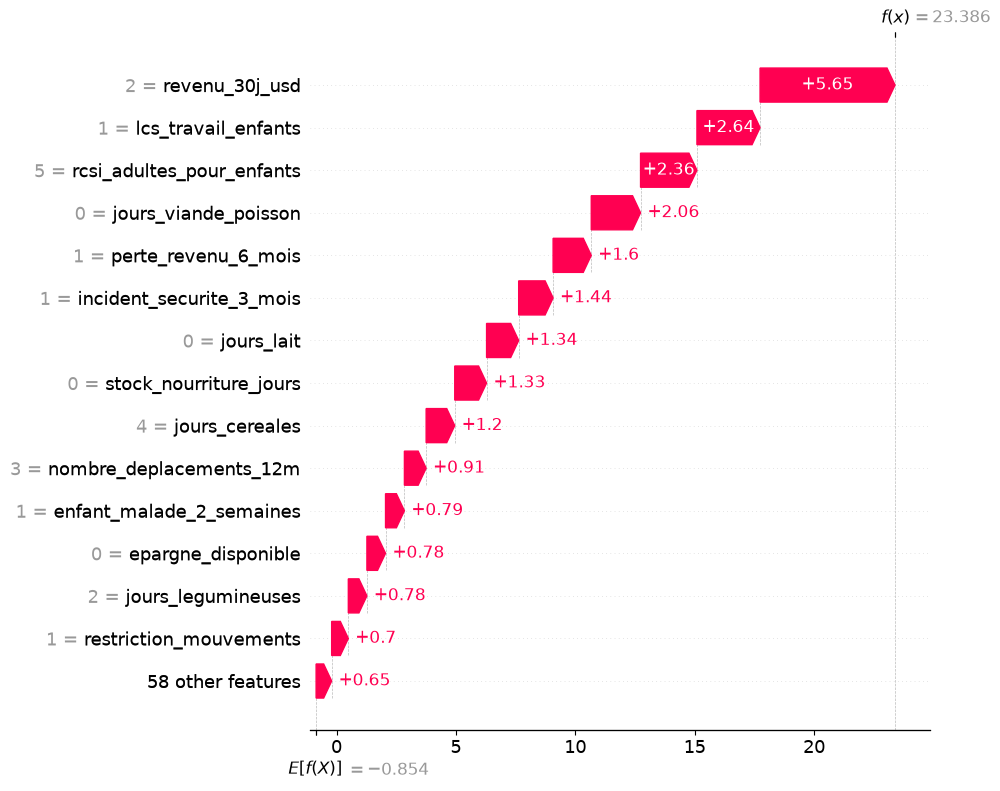

In [87]:
# un ménage éligible : pourquoi le modèle l'a retenu
i = int(np.where(y_test[:500] == 1)[0][0])
shap.plots.waterfall(shap_values[i], max_display = 15)

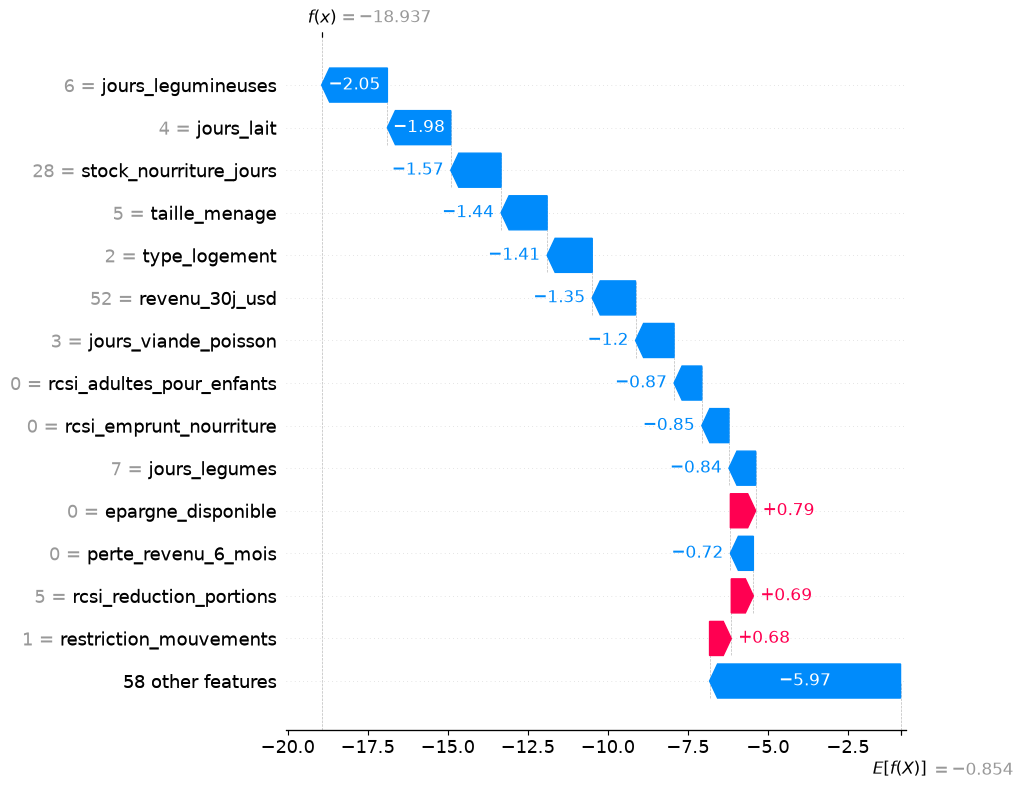

In [88]:
# un ménage non éligible
i = int(np.where(y_test[:500] == 0)[0][0])
shap.plots.waterfall(shap_values[i], max_display = 15)

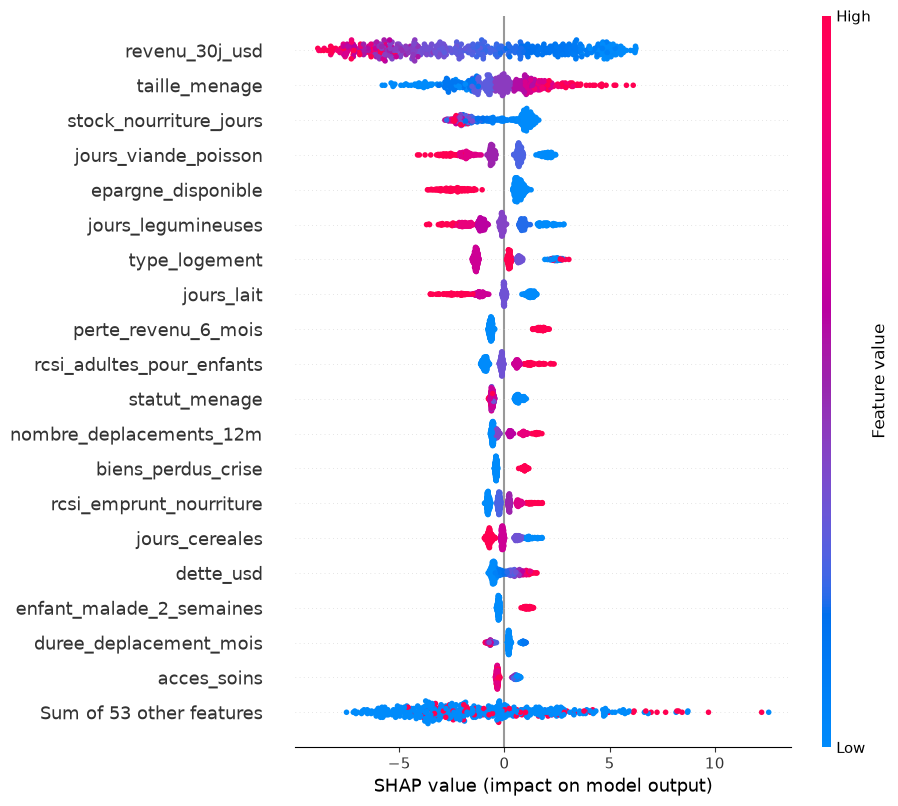

In [89]:
shap.plots.beeswarm(shap_values, max_display = 20)

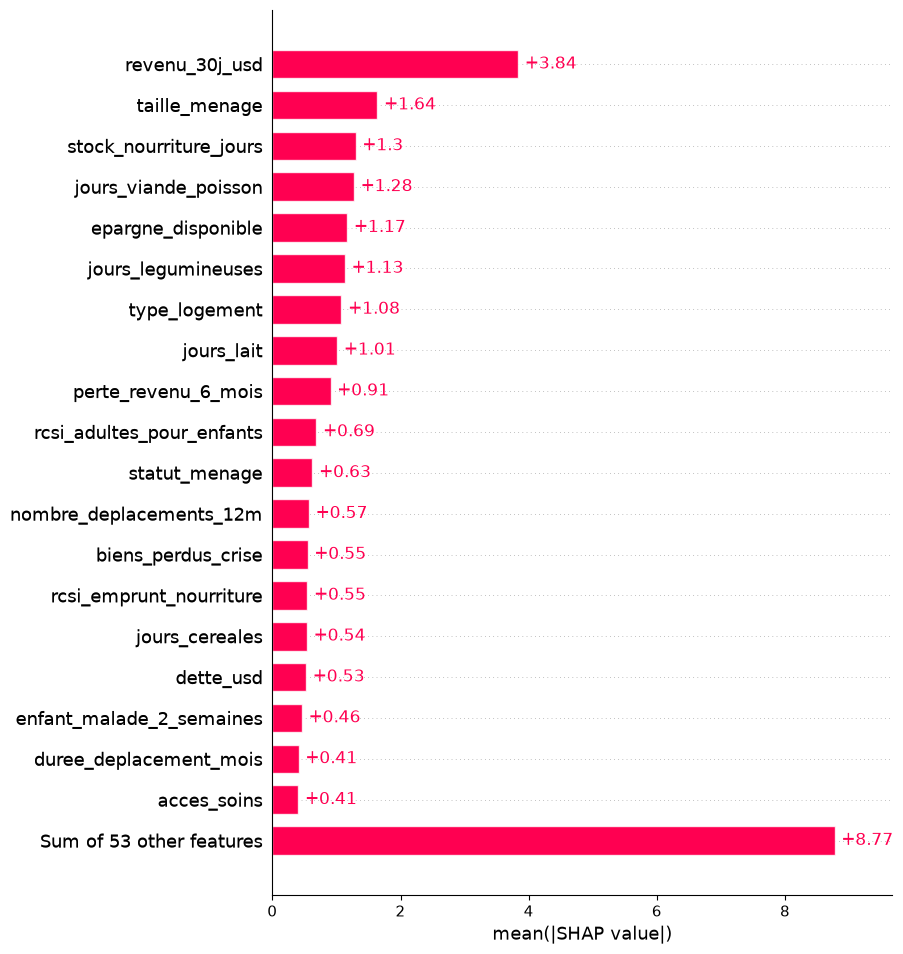

In [90]:
shap.plots.bar(shap_values, max_display = 20)

## Comparaison avec la grille Excel
La grille n'a pas été donnée au modèle. On compare maintenant, sur les mêmes ménages du jeu de test, la décision de la grille Excel (seuil 40 points, exclusions et inclusions automatiques) et celle du modèle, toutes les deux par rapport à la décision de la vérification.

In [91]:
y_grille = df.loc[idx_test, 'decision_grille_excel'].values
y_xgb = xgb.predict(x_test)

comparaison = []
for nom, pred in [('Grille Excel', y_grille), ('XGBoost', y_xgb)]:
    comparaison.append({'model': nom, 'accuracy': accuracy_score(y_test, pred), 'f1_score': f1_score(y_test, pred),
                        'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred)})
df_comparaison = pd.DataFrame(comparaison)
df_comparaison

,model,accuracy,f1_score,recall,precision
0,Grille Excel,0.7881,0.623423,0.584667,0.667682
1,XGBoost,0.9813,0.968608,0.961667,0.975651


In [92]:
model_viz(df_comparaison, "f1_score", "Grille Excel et XGBoost : F1 score sur les données test")
model_viz(df_comparaison, "recall", "Grille Excel et XGBoost : Recall sur les données test")

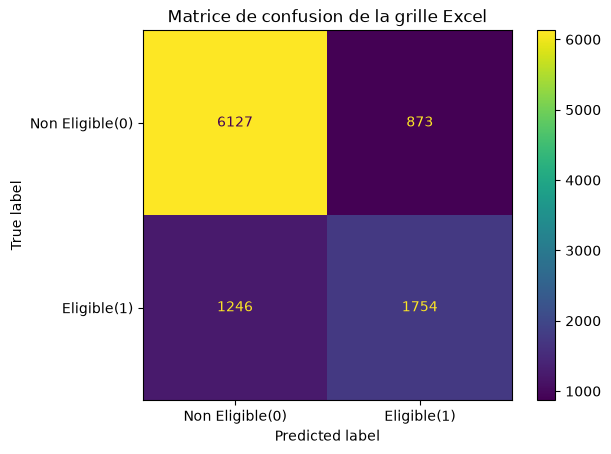

In [93]:
# matrice de confusion de la grille Excel
cnf_matr = confusion_matrix(y_test, y_grille, labels=[0,1])
disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr, display_labels=['Non Eligible(0)','Eligible(1)'])
disp.plot()
plt.title('Matrice de confusion de la grille Excel')
plt.show()

In [94]:
# les ménages éligibles que la grille oublie : le modèle les retrouve-t-il ?
oublies = (y_test == 1) & (y_grille == 0)
print(f"Ménages éligibles oubliés par la grille : {oublies.sum()}")
print(f"Parmi eux, retrouvés par le modèle : {(y_xgb[oublies] == 1).sum()} ({(y_xgb[oublies] == 1).mean():.1%})")

inclus_a_tort = (y_test == 0) & (y_grille == 1)
print(f"Ménages non éligibles retenus par la grille : {inclus_a_tort.sum()}")
print(f"Parmi eux, écartés par le modèle : {(y_xgb[inclus_a_tort] == 0).sum()} ({(y_xgb[inclus_a_tort] == 0).mean():.1%})")

Ménages éligibles oubliés par la grille : 1246
Parmi eux, retrouvés par le modèle : 1167 (93.7%)
Ménages non éligibles retenus par la grille : 873
Parmi eux, écartés par le modèle : 843 (96.6%)


In [95]:
# qui sont les ménages oubliés par la grille ?
test = df.loc[idx_test].copy()
test['groupe'] = np.select([oublies, inclus_a_tort, y_test == 1], ['éligible oublié par la grille', 'retenu à tort par la grille', 'éligible retenu par la grille'], 'non éligible écarté par la grille')
cols = ['score_grille_excel', 'taille_menage', 'revenu_30j_usd', 'stock_nourriture_jours', 'part_depenses_alimentation_pct', 'rcsi_reduction_portions', 'jours_legumineuses', 'jours_viande_poisson']
test.groupby('groupe')[cols].mean().round(1)

,score_grille_excel,taille_menage,revenu_30j_usd,stock_nourriture_jours,part_depenses_alimentation_pct,rcsi_reduction_portions,jours_legumineuses,jours_viande_poisson
groupe,,,,,,,,
non éligible écarté par la grille,25.4,5.7,89.7,23.1,53.4,1.3,3.7,2.2
retenu à tort par la grille,45.0,6.1,70.7,18.3,58.0,1.7,3.5,2.0
éligible oublié par la grille,37.5,6.4,34.3,6.3,66.4,2.7,2.5,1.2
éligible retenu par la grille,52.0,6.8,30.6,5.4,69.6,3.1,2.2,1.1


In [96]:
fig = px.box(test, x = 'groupe', y = 'part_depenses_alimentation_pct', color = 'groupe', title = "Part des dépenses consacrée à la nourriture selon le groupe")
fig.show()

Les ménages oubliés par la grille ont en moyenne 37,5 points, juste sous le seuil de 40. Pourtant leurs réponses montrent une situation difficile : un revenu moyen de 34 $ sur 30 jours (contre 71 $ pour les ménages que la grille retient à tort), 6 jours de réserves de nourriture (contre 18), 66 % du budget pour la nourriture et des portions réduites presque 3 jours par semaine. Ces questions ne sont pas dans la grille, ou y pèsent peu. Le modèle les voit parce qu'il regarde les 72 variables ensemble.

## Conclusion

- Sans la grille, sans son score et sans son seuil, XGBoost apprend la décision de la vérification approfondie à partir des seules réponses de l'enquête ménage.
- **XGBoost est le modèle le plus performant** : sur les données de test, accuracy 98,1 %, F1 96,9 %, recall 96,2 % et précision 97,6 %. Sur chacune des 5 parties de la validation croisée, aucune métrique ne descend sous 96,4 %. Le Gradient Boosting suit (F1 93,9 %), puis la régression logistique et le SVM (91 %), loin devant la grille Excel (62 %).
- La grille Excel reste utile dans les scénarios simples, mais avec 72 variables elle oublie beaucoup de ménages éligibles (1 246 sur 3 000 dans le jeu de test, dont 93,7 % retrouvés par le modèle) et en retient d'autres à tort (873, dont 96,6 % écartés par le modèle). Le modèle voit à grande échelle et aide à la décision ; la décision finale reste revue par un superviseur dans le dashboard.
- Piste pour la suite : utiliser le modèle pour **détecter les anomalies** (réponses incohérentes, enquêteur dont les décisions s'écartent du modèle).

Le modèle déployé dans l'API est entraîné par `training/train.py`, avec la même préparation (LabelEncoder, valeurs "non applicable") et les mêmes paramètres XGBoost.

In [97]:
# télécharger le modèle et les encodeurs (dossier data/, non versionné)
import joblib
joblib.dump(xgb, './data/xgb_model_v6.joblib')
joblib.dump(encoders, './data/encoders_v6.joblib')
joblib.dump(scaler, './data/scaler_v6.joblib')

['./data/scaler_v6.joblib']